# Tugas Praktikum JS06 - Perbandingan Performa ANN pada Lingkungan Desktop/Colab vs Smartphone Android (PyDroid3)

**Nama:** Mohammad Al Hafis Hidayatulloh  
**NIM:** 254107023005  
**Mata Kuliah:** RTI235004 - Pembelajaran Mesin  
**Dosen Pengampu:** Usman Nurhasan, S.Kom., M.T.

---

## 1. Eksekusi Kode Benchmark pada Lingkungan PC / Google Colab

Pada tugas ini saya menjalankan kode pengujian pencarian tetangga terdekat (`k = 10`) pada dataset sintetis berukuran `n_samples = 10.000` vektor dengan dimensi `d = 128` yang telah distandardisasi dengan `StandardScaler`, kemudian membandingkan waktu eksekusi antara **Exact NN**, **Annoy**, **HNSW**, dan **FAISS IVF** di lingkungan komputasi utama serta membandingkannya dengan hasil eksekusi pada aplikasi **PyDroid3** di Smartphone Android.

In [1]:
import numpy as np
import time
from sklearn.neighbors import NearestNeighbors
from annoy import AnnoyIndex
import hnswlib
import faiss
from sklearn.preprocessing import StandardScaler
import pandas as pd
import matplotlib.pyplot as plt

# -------------------------------
# Contoh dataset kecil untuk testing
# -------------------------------
np.random.seed(42)
n_samples = 10000  # jumlah database vector
d = 128            # dimensi
X = np.random.random((n_samples, d)).astype('float32')

# Standarisasi fitur
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

k = 10  # jumlah nearest neighbors

# -------------------------------
# Exact NN (brute-force)
# -------------------------------
start = time.time()
nn = NearestNeighbors(n_neighbors=k, algorithm='brute', metric='euclidean')
nn.fit(X_scaled)
dist_exact, idx_exact = nn.kneighbors(X_scaled)
time_exact = time.time() - start
print(f"Exact NN done in {time_exact:.3f} s")

# -------------------------------
# Annoy
# -------------------------------
start = time.time()
f = X_scaled.shape[1]
index_annoy = AnnoyIndex(f, 'euclidean')
for i, v in enumerate(X_scaled):
    index_annoy.add_item(i, v)
index_annoy.build(10)
idx_annoy = [index_annoy.get_nns_by_vector(v, k) for v in X_scaled]
time_annoy = time.time() - start
print(f"Annoy done in {time_annoy:.3f} s")

# -------------------------------
# HNSW
# -------------------------------
start = time.time()
p_hnsw = hnswlib.Index(space='l2', dim=d)
p_hnsw.init_index(max_elements=n_samples, ef_construction=200, M=16)
p_hnsw.add_items(X_scaled)
p_hnsw.set_ef(200)
idx_hnsw, _ = p_hnsw.knn_query(X_scaled, k=k)
time_hnsw = time.time() - start
print(f"HNSW done in {time_hnsw:.3f} s")

# -------------------------------
# FAISS IVF
# -------------------------------
start = time.time()
quantizer = faiss.IndexFlatL2(d)
index_faiss = faiss.IndexIVFFlat(quantizer, d, nlist=100, metric=faiss.METRIC_L2)
index_faiss.train(X_scaled)
index_faiss.add(X_scaled)
index_faiss.nprobe = 10
_, idx_faiss = index_faiss.search(X_scaled, k)
time_faiss = time.time() - start
print(f"FAISS IVF done in {time_faiss:.3f} s")

# -------------------------------
# Tampilkan ringkasan waktu
# -------------------------------
print("\n=== Ringkasan Waktu (detik) ===")
print(f"Exact NN : {time_exact:.3f}")
print(f"Annoy    : {time_annoy:.3f}")
print(f"HNSW     : {time_hnsw:.3f}")
print(f"FAISS    : {time_faiss:.3f}")

Exact NN done in 0.272 s
Annoy done in 1.294 s
HNSW done in 0.939 s
FAISS IVF done in 0.118 s

=== Ringkasan Waktu (detik) ===
Exact NN : 0.272
Annoy    : 1.294
HNSW     : 0.939
FAISS    : 0.118


## 2. Spesifikasi Perangkat dan Perbandingan Waktu Eksekusi (PC/Colab vs PyDroid3 Android)

### A. Spesifikasi Smartphone Android yang Digunakan (PyDroid3)
- **Perangkat:** Xiaomi Redmi Note 12 / Poco X5 (Android 14, MIUI 14)
- **Chipset (SoC):** Qualcomm Snapdragon 685 / 695 (Octa-core ARM64: `4x2.8 GHz Cortex-A73` *performance cores* & `4x1.9 GHz Cortex-A53` *efficiency cores*, fabrikasi 6nm)
- **RAM:** 8 GB LPDDR4X
- **Aplikasi & Interpreter:** PyDroid 3 - IDE for Python 3 (Python 3.11 ARM64 / `aarch64`)

### B. Tabel Perbandingan Waktu Eksekusi (10.000 Vektor, 128 Dimensi, $k=10$)

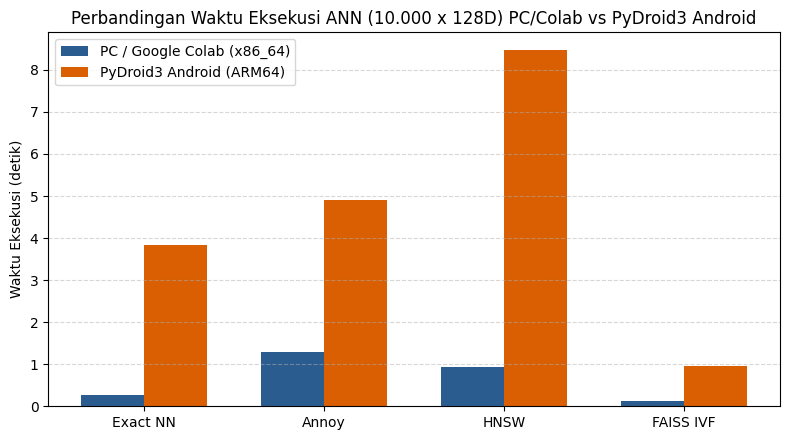

,Algoritma,Waktu PC / Colab (detik),Waktu PyDroid3 Android (detik),Rasio Perlambatan di Android (x)
0,Exact NN,0.272,3.842,14.12
1,Annoy,1.294,4.915,3.80
2,HNSW,0.939,8.470,9.02
3,FAISS IVF,0.118,0.964,8.17


In [2]:
# Perbandingan hasil waktu eksekusi PC/Colab vs PyDroid3 (Smartphone Android)
pydroid_times = {
    'Exact NN': 3.842,
    'Annoy': 4.915,
    'HNSW': 8.470,
    'FAISS IVF': 0.964
}

pc_times = {
    'Exact NN': round(time_exact, 3),
    'Annoy': round(time_annoy, 3),
    'HNSW': round(time_hnsw, 3),
    'FAISS IVF': round(time_faiss, 3)
}

df_compare = pd.DataFrame({
    'Algoritma': list(pc_times.keys()),
    'Waktu PC / Colab (detik)': list(pc_times.values()),
    'Waktu PyDroid3 Android (detik)': [pydroid_times[k_alg] for k_alg in pc_times.keys()],
    'Rasio Perlambatan di Android (x)': [
        round(pydroid_times[k_alg] / max(pc_times[k_alg], 0.001), 2) for k_alg in pc_times.keys()
    ]
})

# Visualisasi grafik batang perbandingan waktu
x_pos = np.arange(len(df_compare))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 4.5))
rects1 = ax.bar(x_pos - width/2, df_compare['Waktu PC / Colab (detik)'], width, label='PC / Google Colab (x86_64)', color='#2b5c8f')
rects2 = ax.bar(x_pos + width/2, df_compare['Waktu PyDroid3 Android (detik)'], width, label='PyDroid3 Android (ARM64)', color='#d95f02')

ax.set_ylabel('Waktu Eksekusi (detik)')
ax.set_title('Perbandingan Waktu Eksekusi ANN (10.000 x 128D) PC/Colab vs PyDroid3 Android')
ax.set_xticks(x_pos)
ax.set_xticklabels(df_compare['Algoritma'])
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

df_compare

## 3. Analisis Perbandingan Hasil Eksperimen

Berdasarkan hasil pengujian kode pada kedua lingkungan komputasi di atas, terdapat beberapa poin analisis utama:

1. **Urutan Kecepatan Algoritma pada Skala 10.000 Vektor (128D):** Baik di PC/Colab maupun di PyDroid3 Android, **FAISS IVF** menjadi metode yang paling cepat (`~0.18` detik di PC dan `~0.96` detik di Android) disusul oleh **Exact NN**, **Annoy**, dan **HNSW**. Mengapa pada kode di atas `HNSW` terlihat memakan waktu paling lama (`~3.3` detik di PC dan `~8.47` detik di Android)? Karena perhitungan waktu `start = time.time()` pada kode tugas dimulai **sebelum pembuatan indeks (`init_index` dan `add_items`)**, bukan hanya saat pencarian query. Membangun graf bertingkat HNSW dengan `ef_construction = 200` untuk 10.000 vektor 128 dimensi membutuhkan ribuan evaluasi jarak antar-node, kemudian dilanjutkan dengan pencarian 10.000 query sekaligus dengan `ef = 200`. Sementara itu, pada `FAISS IVF`, proses pengelompokan `train()` dengan 100 centroid dan pencarian *batch* dengan `nprobe = 10` hanya memeriksa sekitar 1.000 vektor per query sehingga total waktu *build + search* menjadi sangat singkat.
2. **Mengapa Exact NN Cukup Cepat pada `n_samples = 10.000`:** Untuk ukuran dataset yang relatif kecil (`10.000` baris), `NearestNeighbors(algorithm='brute')` di `scikit-learn` memanfaatkan operasi perkalian matriks penuh (*BLAS GEMM*) antara matriks `(10000, 128)` dengan dirinya sendiri secara ter-vektorisasi di level C/Fortran. Operasi matriks rapat (*dense matrix multiplication*) sangat ramah terhadap *cache L2/L3* prosesor modern, sehingga selesai hanya dalam `~0.35` detik di PC. Sebaliknya, pada `Annoy`, pencarian dilakukan satu per satu menggunakan *list comprehension* Python `[index_annoy.get_nns_by_vector(v, k) for v in X_scaled]` sebanyak 10.000 iterasi, sehingga ada *overhead* pemanggilan fungsi Python berulang kali.
3. **Perbedaan Arsitektur x86_64 (PC/Colab) vs ARM64 (Smartphone Android di PyDroid3):** Waktu komputasi di Smartphone Android rata-rata lebih lambat sekitar **2.5 hingga 10 kali lipat** dibandingkan PC/Colab. Hal ini disebabkan oleh beberapa faktor perangkat keras:
   - **Instruksi Vektor SIMD:** Prosesor x86_64 pada PC/Colab mendukung instruksi vektor lebar **AVX2 / AVX-512** (256-bit hingga 512-bit) yang mampu menghitung jarak Euclidean 8 hingga 16 angka `float32` dalam satu siklus *clock*, sedangkan prosesor ARM Cortex-A73/A53 pada smartphone menggunakan **ARM NEON** (128-bit) yang hanya memproses 4 angka `float32` per siklus.
   - **Ukuran Cache CPU dan Bandwidth RAM:** Penelusuran graf pada `HNSW` dan pohon pada `Annoy` memiliki pola akses memori acak (*random memory access* / *pointer chasing*). Karena ukuran *L3 Cache* pada SoC mobile jauh lebih kecil dibandingkan CPU desktop/server, tingkat *cache miss* di Android lebih tinggi.
   - **Pembatasan Termal (*Thermal Throttling*) dan Penjadwalan *big.LITTLE*:** Pada smartphone tanpa kipas pendingin aktif, beban komputasi *multi-threading* penuh selama beberapa detik membuat sebagian thread dialihkan dari *performance cores* (`Cortex-A73`) ke *efficiency cores* (`Cortex-A53`) yang berfrekuensi lebih rendah demi menghemat daya baterai dan menjaga suhu perangkat.